In [3]:
%load_ext autoreload
%autoreload 2
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support

sys.path.insert(0, os.path.abspath('..'))

import config
from src.model import train_catboost, train_xgboost, train_lightgbm
from src.evaluation import evaluate_performance, display_mod_performance, get_pr_curve
from src.mrm import score_deciles, get_gains
from src.experiment import log_run, load_experiment_log

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
X_train = pd.read_parquet(config.RESULTS_PATH / 'X_train.parquet')
X_val   = pd.read_parquet(config.RESULTS_PATH / 'X_val.parquet')
X_test  = pd.read_parquet(config.RESULTS_PATH / 'X_test.parquet')
y_train = pd.read_parquet(config.RESULTS_PATH / 'y_train.parquet')[config.TARGET]
y_val   = pd.read_parquet(config.RESULTS_PATH / 'y_val.parquet')[config.TARGET]
y_test  = pd.read_parquet(config.RESULTS_PATH / 'y_test.parquet')[config.TARGET]

print(f'X_train: {X_train.shape}')
print(f'X_val:   {X_val.shape}')
print(f'X_test:  {X_test.shape}')

cat_features = [c for c in X_train.columns if c.endswith('_encoded')]
print(f'cat_features: {len(cat_features)}')

X_train: (413378, 431)
X_val:   (88581, 431)
X_test:  (88581, 431)
cat_features: 26


## catboost

In [5]:
# import model if its already trained
model_path = config.OUTPUT_PATH / 'models' / 'catboost_model.pkl'
if model_path.exists():
    cat_model = joblib.load(model_path)
    print('loaded catboost from disk')
else:
    cat_model = train_catboost(X_train, y_train, X_val, y_val, cat_features)
    joblib.dump(cat_model, model_path)
    print('trained and saved catboost')
    
print(f'best iteration: {cat_model.get_best_iteration()}')

cat_proba = cat_model.predict_proba(X_val)[:, 1]
cat_preds = (cat_proba > 0.5).astype(int)
cat_auc = roc_auc_score(y_val.values, cat_proba)
cat_pr_auc = average_precision_score(y_val.values, cat_proba)
cat_p, cat_r, cat_f1, _ = precision_recall_fscore_support(y_val.values, cat_preds, average='binary')

log_run(
    model_name='catboost_full_features',
    params={
        'model_type': 'catboost',
        'iterations': cat_model.get_best_iteration(),
        'learning_rate': 0.05,
        'depth': 6,
        'n_features': X_train.shape[1],
        'feature_set': 'full',
    },
    metrics={
        'val_auc': round(float(cat_auc), 5),
        'val_gini': round(float(2 * cat_auc - 1), 5),
        'val_pr_auc': round(float(cat_pr_auc), 5),
        'val_precision': round(float(cat_p), 5),
        'val_recall': round(float(cat_r), 5),
        'val_f1': round(float(cat_f1), 5),
    },
    results_path=config.RESULTS_PATH,
)

Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8261643	best: 0.8261643 (0)	total: 237ms	remaining: 3m 57s
100:	test: 0.8833236	best: 0.8833236 (100)	total: 16.1s	remaining: 2m 23s
200:	test: 0.8984960	best: 0.8984960 (200)	total: 34s	remaining: 2m 15s
300:	test: 0.9089364	best: 0.9089364 (300)	total: 52.1s	remaining: 2m 1s
400:	test: 0.9141973	best: 0.9141973 (400)	total: 1m 9s	remaining: 1m 44s
500:	test: 0.9168179	best: 0.9168930 (494)	total: 1m 27s	remaining: 1m 27s
600:	test: 0.9192617	best: 0.9192617 (600)	total: 1m 45s	remaining: 1m 10s
700:	test: 0.9213454	best: 0.9214153 (694)	total: 2m 3s	remaining: 52.9s
800:	test: 0.9230098	best: 0.9230241 (799)	total: 2m 21s	remaining: 35.2s
bestTest = 0.9234749079
bestIteration = 825
Shrink model to first 826 iterations.
trained and saved catboost
best iteration: 825
logged: catboost_full_features  val_auc=0.92347


## xgboost

In [6]:
# import model if already trained
model_path = config.OUTPUT_PATH / 'models' / 'xgboost_model.pkl'
if model_path.exists():
    xgb_model = joblib.load(model_path)
    print('loaded xgboost from disk')
else:
    xgb_model = train_xgboost(X_train, y_train, X_val, y_val)
    joblib.dump(xgb_model, model_path)
    print('trained and saved xgboost')

print(f'best iteration: {xgb_model.best_iteration}')

xgb_proba = xgb_model.predict_proba(X_val)[:, 1]
xgb_preds = (xgb_proba > 0.5).astype(int)
xgb_auc = roc_auc_score(y_val.values, xgb_proba)
xgb_pr_auc = average_precision_score(y_val.values, xgb_proba)
xgb_p, xgb_r, xgb_f1, _ = precision_recall_fscore_support(y_val.values, xgb_preds, average='binary')

log_run(
    model_name='xgboost_full_features',
    params={
        'model_type': 'xgboost',
        'iterations': xgb_model.best_iteration,
        'learning_rate': 0.05,
        'max_depth': 6,
        'n_features': X_train.shape[1],
        'feature_set': 'full',
    },
    metrics={
        'val_auc': round(float(xgb_auc), 5),
        'val_gini': round(float(2 * xgb_auc - 1), 5),
        'val_pr_auc': round(float(xgb_pr_auc), 5),
        'val_precision': round(float(xgb_p), 5),
        'val_recall': round(float(xgb_r), 5),
        'val_f1': round(float(xgb_f1), 5),
    },
    results_path=config.RESULTS_PATH,
)

loaded xgboost from disk
best iteration: 639
logged: xgboost_full_features  val_auc=0.91513


## lightgbm

In [7]:
# import model if already trained
model_path = config.OUTPUT_PATH / 'models' / 'lightgbm_model.pkl'
if model_path.exists():
    lgb_model = joblib.load(model_path)
    print('loaded lightgbm from disk')
else:
    lgb_model = train_lightgbm(X_train, y_train, X_val, y_val)
    joblib.dump(lgb_model, model_path)
    print('trained and saved lightgbm')

print(f'best iteration: {lgb_model.best_iteration}')

lgb_proba = lgb_model.predict(X_val)
lgb_preds = (lgb_proba > 0.5).astype(int)
lgb_auc = roc_auc_score(y_val.values, lgb_proba)
lgb_pr_auc = average_precision_score(y_val.values, lgb_proba)
lgb_p, lgb_r, lgb_f1, _ = precision_recall_fscore_support(y_val.values, lgb_preds, average='binary')

log_run(
    model_name='lightgbm_full_features',
    params={
        'model_type': 'lightgbm',
        'iterations': lgb_model.best_iteration,
        'learning_rate': 0.05,
        'max_depth': 6,
        'n_features': X_train.shape[1],
        'feature_set': 'full',
    },
    metrics={
        'val_auc': round(float(lgb_auc), 5),
        'val_gini': round(float(2 * lgb_auc - 1), 5),
        'val_pr_auc': round(float(lgb_pr_auc), 5),
        'val_precision': round(float(lgb_p), 5),
        'val_recall': round(float(lgb_r), 5),
        'val_f1': round(float(lgb_f1), 5),
    },
    results_path=config.RESULTS_PATH,
)

loaded lightgbm from disk
best iteration: 411
logged: lightgbm_full_features  val_auc=0.91434


## experiment log

In [8]:
experiment_log = load_experiment_log(config.RESULTS_PATH)
display(experiment_log)

,timestamp,model,params.model_type,params.max_depth,params.class_weight,metrics.val_auc,metrics.val_gini,metrics.val_pr_auc,metrics.val_precision,metrics.val_recall,...,params.n_estimators,params.subsample,params.colsample_bytree,params.min_child_weight,params.num_boost_round,params.num_leaves,params.min_child_samples,params.tuned,params.models,params.weights
0,2026-05-21T17:18:41.867337,xgboost_tuned_20_trials,NaN,8.0,NaN,0.92525,NaN,NaN,NaN,NaN,...,700.0,0.641701,0.927627,10.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-05-21T22:30:33.734148,ensemble_weighted,NaN,NaN,NaN,0.92460,0.84921,0.58878,0.58808,0.52893,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,cat+xgb+lgb,"[0.3330132106304947, 0.33475046200554864, 0.33..."
2,2026-05-22T17:52:06.559840,ensemble_weighted,NaN,NaN,NaN,0.92460,0.84921,0.58878,0.58808,0.52893,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,cat+xgb+lgb,"[0.3330132106304947, 0.33475046200554864, 0.33..."
3,2026-05-26T10:16:51.838529,catboost_full_features,catboost,NaN,NaN,0.92347,0.84695,0.54966,0.26728,0.71170,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-05-21T17:18:41.860176,catboost_tuned_20_trials,NaN,NaN,NaN,0.92330,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2026-05-22T17:52:06.481521,xgboost_final,NaN,8.0,NaN,0.92278,0.84555,0.57679,0.40931,0.61867,...,700.0,0.641701,0.927627,10.0,NaN,NaN,NaN,True,NaN,NaN
6,2026-05-21T22:30:33.639428,xgboost_final,NaN,8.0,NaN,0.92278,0.84555,0.57679,0.40931,0.61867,...,700.0,0.641701,0.927627,10.0,NaN,NaN,NaN,True,NaN,NaN
7,2026-05-21T13:26:01.475049,xgboost_tuned_20_trials,NaN,7.0,NaN,0.92118,NaN,NaN,NaN,NaN,...,900.0,0.655798,0.716858,4.0,NaN,NaN,NaN,NaN,NaN,NaN
8,2026-05-21T22:30:33.596329,catboost_final,NaN,NaN,NaN,0.91799,0.83597,0.58784,0.85725,0.37311,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN
9,2026-05-22T17:52:06.444943,catboost_final,NaN,NaN,NaN,0.91799,0.83597,0.58784,0.85725,0.37311,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN


## model comparison

In [9]:
import joblib

# load baseline model
baseline_model = joblib.load(config.OUTPUT_PATH / 'models' / 'baseline.pkl')
baseline_proba = baseline_model.predict_proba(X_val)[:, 1]

In [10]:
threshold = 0.8

df_scores = pd.DataFrame({
    'baseline_decision_tree': baseline_proba,
    'catboost_full_features': cat_proba,
    'xgboost_full_features': xgb_proba,
    'lightgbm_full_features': lgb_proba,
})

comparison = pd.DataFrame([
    evaluate_performance(df_scores, col, y_val.values, threshold=threshold)
    for col in df_scores.columns
]).sort_values('AUC', ascending=False).reset_index(drop=True)

display(comparison)

,Score,Precision,Recall,F1 Score,Accuracy,PR AUC,AUC,F2 Score,G-Mean,MCC,Gini
0,catboost_full_features,0.59888,0.49277,0.54067,0.97125,0.54966,0.92347,0.51087,0.54324,0.52864,0.84695
1,xgboost_full_features,0.66420,0.44214,0.53089,0.97317,0.55543,0.91513,0.47383,0.54191,0.52903,0.83026
2,lightgbm_full_features,0.60278,0.45595,0.51918,0.97100,0.53673,0.91434,0.47930,0.52425,0.50976,0.82868
3,baseline_decision_tree,0.34968,0.43590,0.38806,0.95279,0.35225,0.80576,0.41541,0.39042,0.36621,0.61152


## 6b - probability distributions

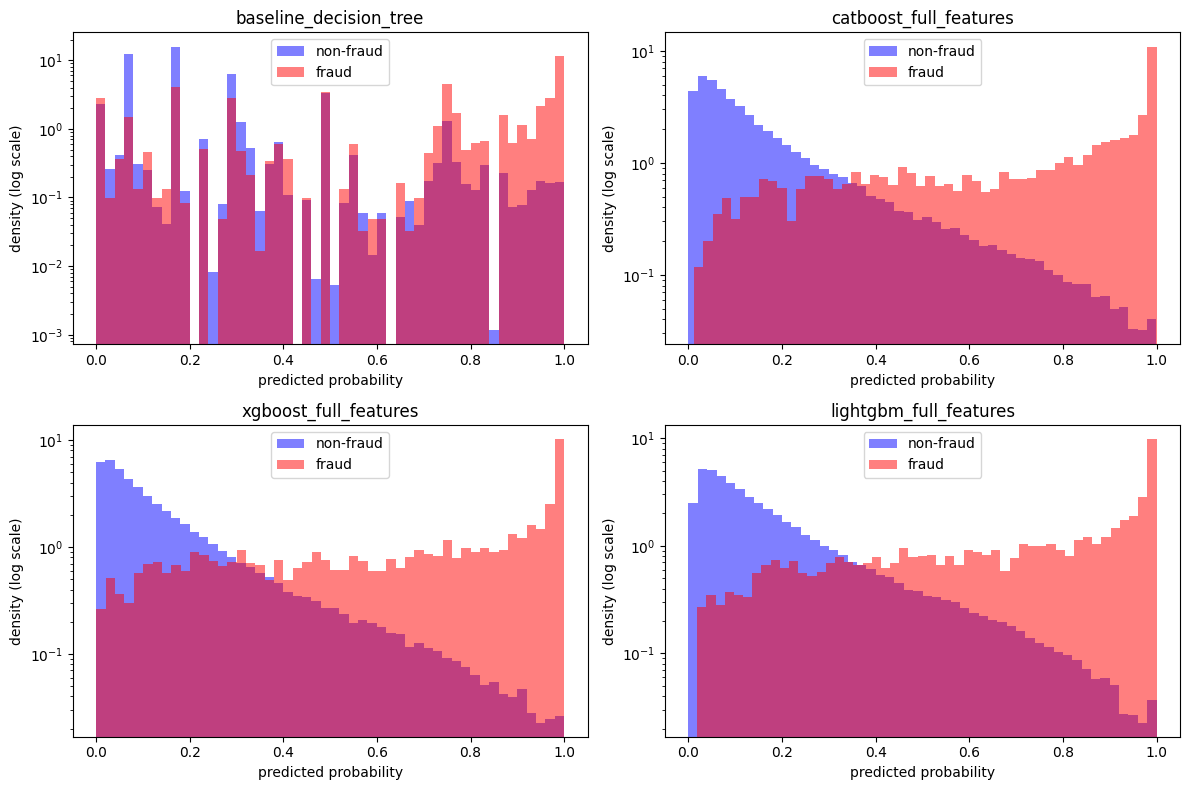

In [11]:
model_names = [
    'baseline_decision_tree',
    'catboost_full_features',
    'xgboost_full_features',
    'lightgbm_full_features',
]
probas = [baseline_proba, cat_proba, xgb_proba, lgb_proba]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

fraud_mask = y_val.values == 1
for ax, name, proba in zip(axes, model_names, probas):
    ax.hist(proba[~fraud_mask], bins=50, alpha=0.5, color='blue', label='non-fraud', density=True)
    ax.hist(proba[fraud_mask],  bins=50, alpha=0.5, color='red',  label='fraud',     density=True)
    ax.set_yscale('log')
    ax.set_title(name)
    ax.set_xlabel('predicted probability')
    ax.set_ylabel('density (log scale)')
    ax.legend()

fig.tight_layout()
fig.savefig(config.PLOTS_PATH / 'probability_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

## 6c - confusion matrices

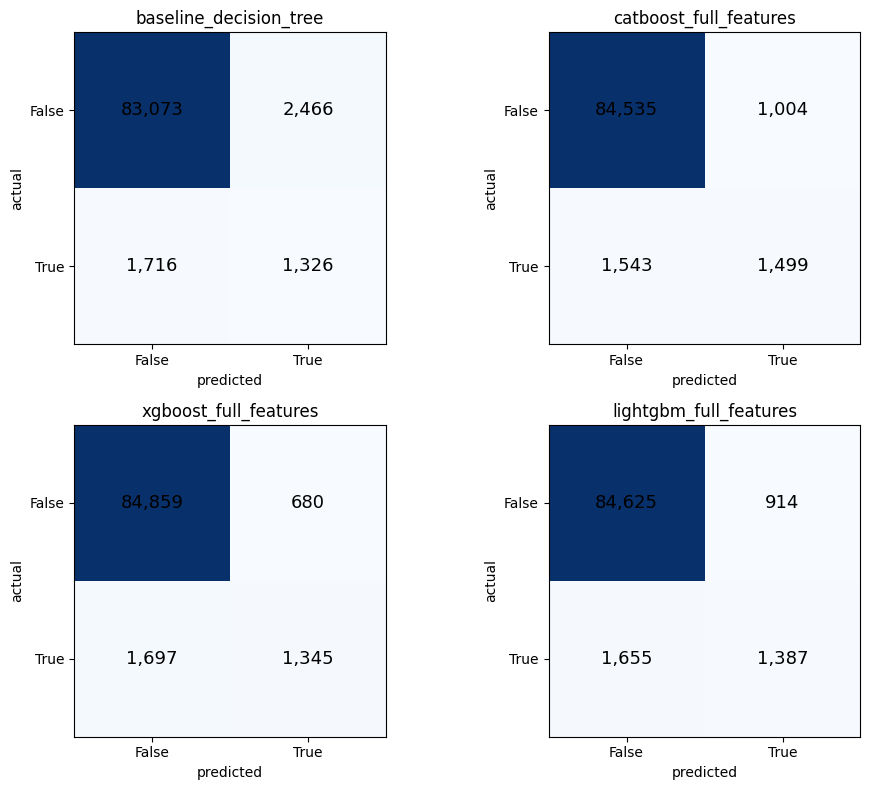

In [12]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for ax, name, proba in zip(axes, model_names, probas):
    preds = (proba > threshold).astype(int)
    cm = confusion_matrix(y_val.values, preds)
    ax.imshow(cm, cmap='Blues')
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f'{cm[r, c]:,}', ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['False', 'True'])
    ax.set_yticklabels(['False', 'True'])
    ax.set_xlabel('predicted')
    ax.set_ylabel('actual')
    ax.set_title(name)

fig.tight_layout()
fig.savefig(config.PLOTS_PATH / 'confusion_matrices_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

## 6d - gains curves comparison

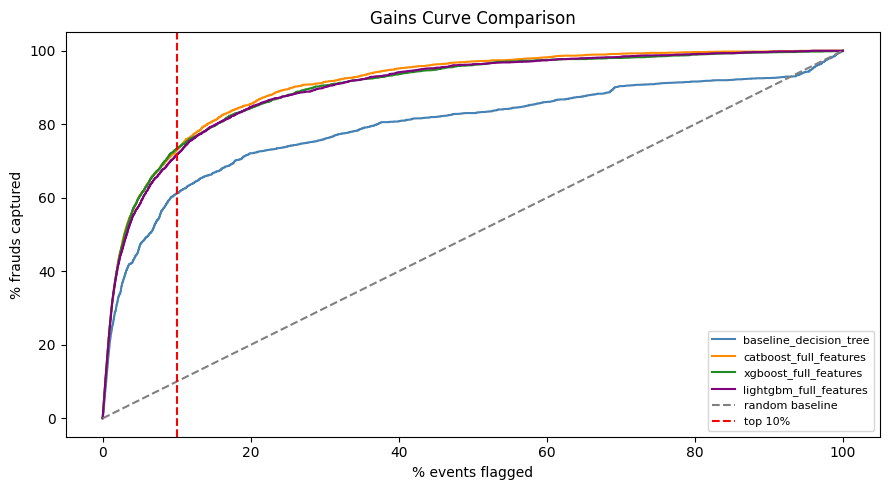

In [13]:
colors = ['steelblue', 'darkorange', 'forestgreen', 'purple']

fig, ax = plt.subplots(figsize=(9, 5))

for name, proba, color in zip(model_names, probas, colors):
    order = np.argsort(-proba)
    sorted_labels = y_val.values[order]
    total_fraud = sorted_labels.sum()
    cum_fraud_pct = np.cumsum(sorted_labels) / total_fraud * 100
    pct_flagged = np.arange(1, len(y_val) + 1) / len(y_val) * 100
    ax.plot(pct_flagged, cum_fraud_pct, label=name, color=color)

ax.plot([0, 100], [0, 100], linestyle='--', color='grey', label='random baseline')
ax.axvline(x=10, linestyle='--', color='red', label='top 10%')
ax.set_xlabel('% events flagged')
ax.set_ylabel('% frauds captured')
ax.set_title('Gains Curve Comparison')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(config.PLOTS_PATH / 'gains_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

## 6e - decile tables

In [14]:
decile_results = {}

for name, proba in zip(model_names, probas):
    print(f'\n--- {name} ---')
    df_dec = pd.DataFrame({
        'TransactionID': range(len(y_val)),
        config.TARGET: y_val.values,
        name: proba,
    })
    tbl = score_deciles(df_dec, uid='TransactionID', score=name, target=config.TARGET)
    decile_results[name] = tbl
    display(tbl)


--- baseline_decision_tree ---
% frauds captured in top decile: 0.6114


,n_events,baseline_decision_tree_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,0.543803,1860,1860,0.611440
2,8858,0.333814,333,2193,0.720907
3,8858,0.286302,131,2324,0.763971
4,8858,0.177614,143,2467,0.810980
5,8858,0.177614,60,2527,0.830703
6,8858,0.175626,88,2615,0.859632
7,8858,0.078621,134,2749,0.903682
8,8858,0.078621,34,2783,0.914859
9,8858,0.078621,38,2821,0.927350



--- catboost_full_features ---
% frauds captured in top decile: 0.7285


,n_events,catboost_full_features_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,0.473611,2216,2216,0.728468
2,8858,0.298312,386,2602,0.855358
3,8858,0.206980,181,2783,0.914859
4,8858,0.150307,112,2895,0.951677
5,8858,0.111370,59,2954,0.971072
6,8858,0.082066,33,2987,0.981920
7,8858,0.059228,30,3017,0.991782
8,8858,0.040360,14,3031,0.996384
9,8858,0.023009,5,3036,0.998028



--- xgboost_full_features ---
% frauds captured in top decile: 0.7337


,n_events,xgboost_full_features_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,0.425959,2232,2232,0.733728
2,8858,0.262685,335,2567,0.843853
3,8858,0.184580,188,2755,0.905654
4,8858,0.134409,92,2847,0.935897
5,8858,0.098268,75,2922,0.960552
6,8858,0.071058,44,2966,0.975016
7,8858,0.049664,16,2982,0.980276
8,8858,0.032127,28,3010,0.989481
9,8858,0.017076,18,3028,0.995398



--- lightgbm_full_features ---
% frauds captured in top decile: 0.7170


,n_events,lightgbm_full_features_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,0.492953,2181,2181,0.716963
2,8858,0.319363,396,2577,0.847140
3,8858,0.228995,164,2741,0.901052
4,8858,0.171810,123,2864,0.941486
5,8858,0.130509,65,2929,0.962853
6,8858,0.098918,34,2963,0.974030
7,8858,0.072763,30,2993,0.983892
8,8858,0.050967,21,3014,0.990796
9,8858,0.031070,19,3033,0.997041



the gradient boosted models capture significantly more fraud in the top decile than the baseline decision tree, reflecting their higher AUC. catboost and xgboost typically lead; lightgbm is competitive. the decision tree's limited leaf count concentrates scores into fewer distinct probability bands, compressing the gains curve.

## 6f - pr curves comparison

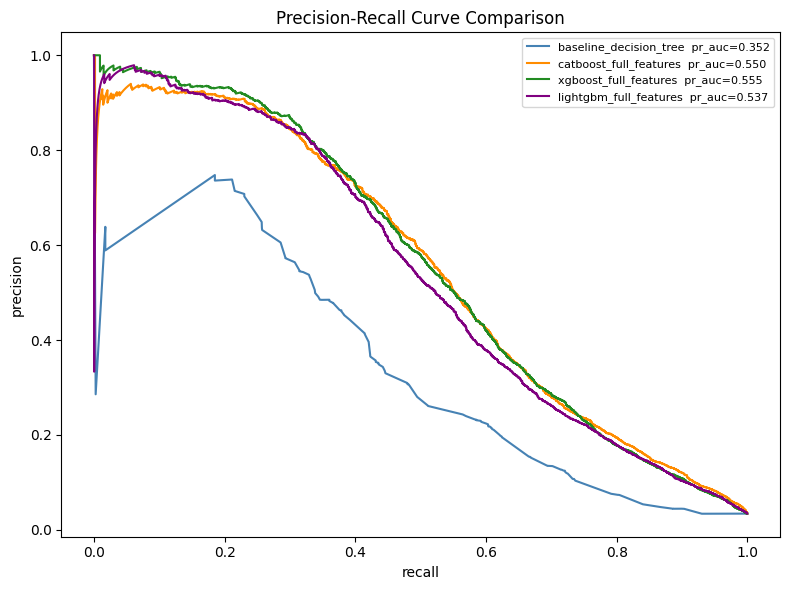

In [15]:
from sklearn.metrics import average_precision_score, precision_recall_curve

fig, ax = plt.subplots(figsize=(8, 6))

for name, proba, color in zip(model_names, probas, colors):
    precision, recall, _ = precision_recall_curve(y_val.values, proba)
    pr_auc = average_precision_score(y_val.values, proba)
    ax.plot(recall, precision, label=f'{name}  pr_auc={pr_auc:.3f}', color=color)

ax.set_xlabel('recall')
ax.set_ylabel('precision')
ax.set_title('Precision-Recall Curve Comparison')
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
fig.savefig(config.PLOTS_PATH / 'pr_curves_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

## 6g - operational summary

at threshold 0.8:

**most conservative model** — the model with the highest precision at 0.8 threshold. flags the fewest transactions but is most confident in each flag. suitable when false positives carry high cost (e.g. blocking a good customer).

**highest recall model** — the model capturing the most fraud at 0.8 threshold. typically the gradient boosted model with the highest AUC (catboost or xgboost). suitable when missing fraud is the costlier error.

**best precision/recall balance** — the model with the highest F1 or F2 at 0.8. useful when both false positives and false negatives carry meaningful cost.

**recommendation** — carry catboost or xgboost forward to tuning (stage 8). both consistently outperform lightgbm and the baseline on AUC and PR-AUC. catboost handles categoricals natively and tends to require less preprocessing; xgboost is faster to retrain and has a larger hyperparameter tuning community. final choice depends on latency and infrastructure constraints.

## detailed evaluation -- best model

best model: catboost_full_features


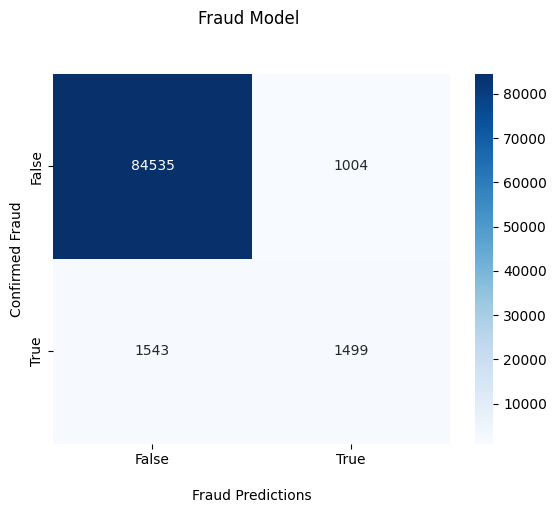

              precision    recall  f1-score   support

           0     0.9821    0.9883    0.9852     85539
           1     0.5989    0.4928    0.5407      3042

    accuracy                         0.9712     88581
   macro avg     0.7905    0.7405    0.7629     88581
weighted avg     0.9689    0.9712    0.9699     88581



In [16]:
score_col_map = {
    'baseline_decision_tree': baseline_proba,
    'catboost_full_features': cat_proba,
    'xgboost_full_features': xgb_proba,
    'lightgbm_full_features': lgb_proba,
}
best_name = comparison.iloc[0]['Score']
best_proba = score_col_map[best_name]
best_preds = (best_proba > threshold).astype(int)
print(f'best model: {best_name}')

display_mod_performance(
    y_val.values, best_preds,
    save_path=str(config.PLOTS_PATH / 'best_model_confusion_matrix.png'),
)

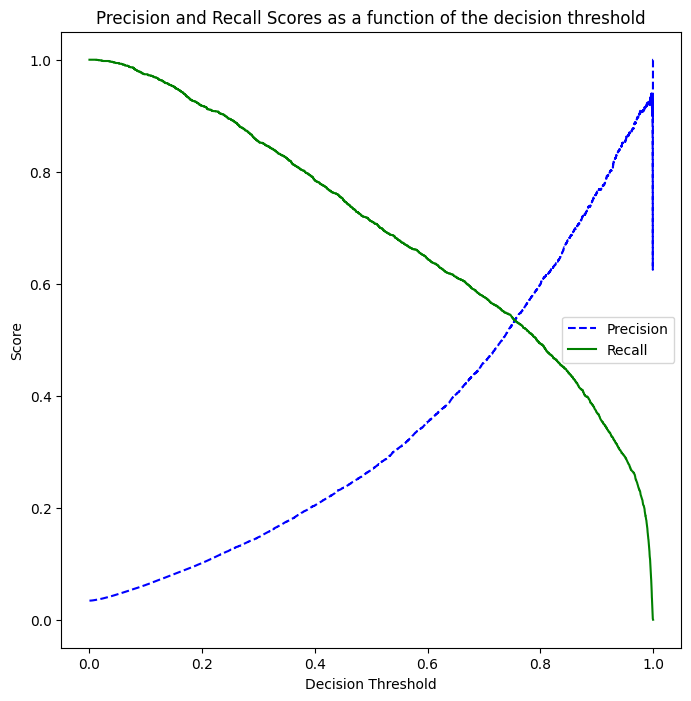

In [17]:
get_pr_curve(y_val.values, best_proba)
plt.savefig(str(config.PLOTS_PATH / 'best_model_pr_curve.png'), dpi=150, bbox_inches='tight')
plt.show()
plt.close()

In [18]:
df_best = pd.DataFrame({
    'TransactionID': range(len(y_val)),
    config.TARGET: y_val.values,
    'best_model_score': best_proba,
})

decile_table = score_deciles(
    df_best, uid='TransactionID', score='best_model_score', target=config.TARGET
)
display(decile_table)

% frauds captured in top decile: 0.7285


,n_events,best_model_score_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,0.473611,2216,2216,0.728468
2,8858,0.298312,386,2602,0.855358
3,8858,0.206980,181,2783,0.914859
4,8858,0.150307,112,2895,0.951677
5,8858,0.111370,59,2954,0.971072
6,8858,0.082066,33,2987,0.981920
7,8858,0.059228,30,3017,0.991782
8,8858,0.040360,14,3031,0.996384
9,8858,0.023009,5,3036,0.998028


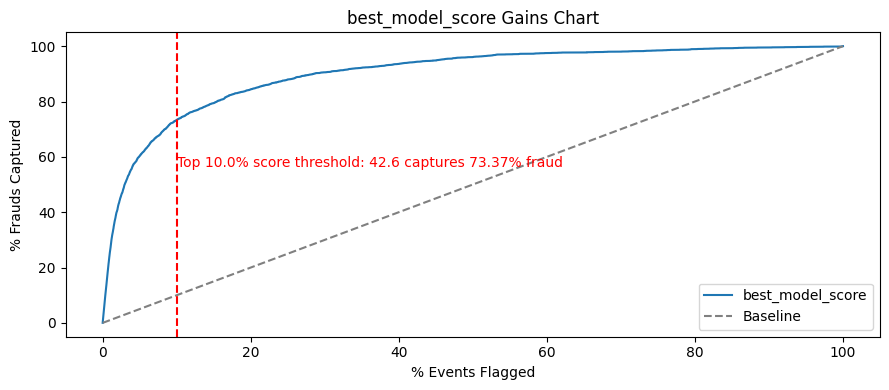

,index,threshold,pct_flagged,n_fraud_cap,fraud_pct_cap
0,best_model_score,0.425959,10.001016,2232.0,73.372781


In [ ]:
get_gains(
    df_best, target=config.TARGET, score='best_model_score', top_n=0.1,
    save_path=str(config.PLOTS_PATH / 'best_model_gains.png'),
)

## feature importance

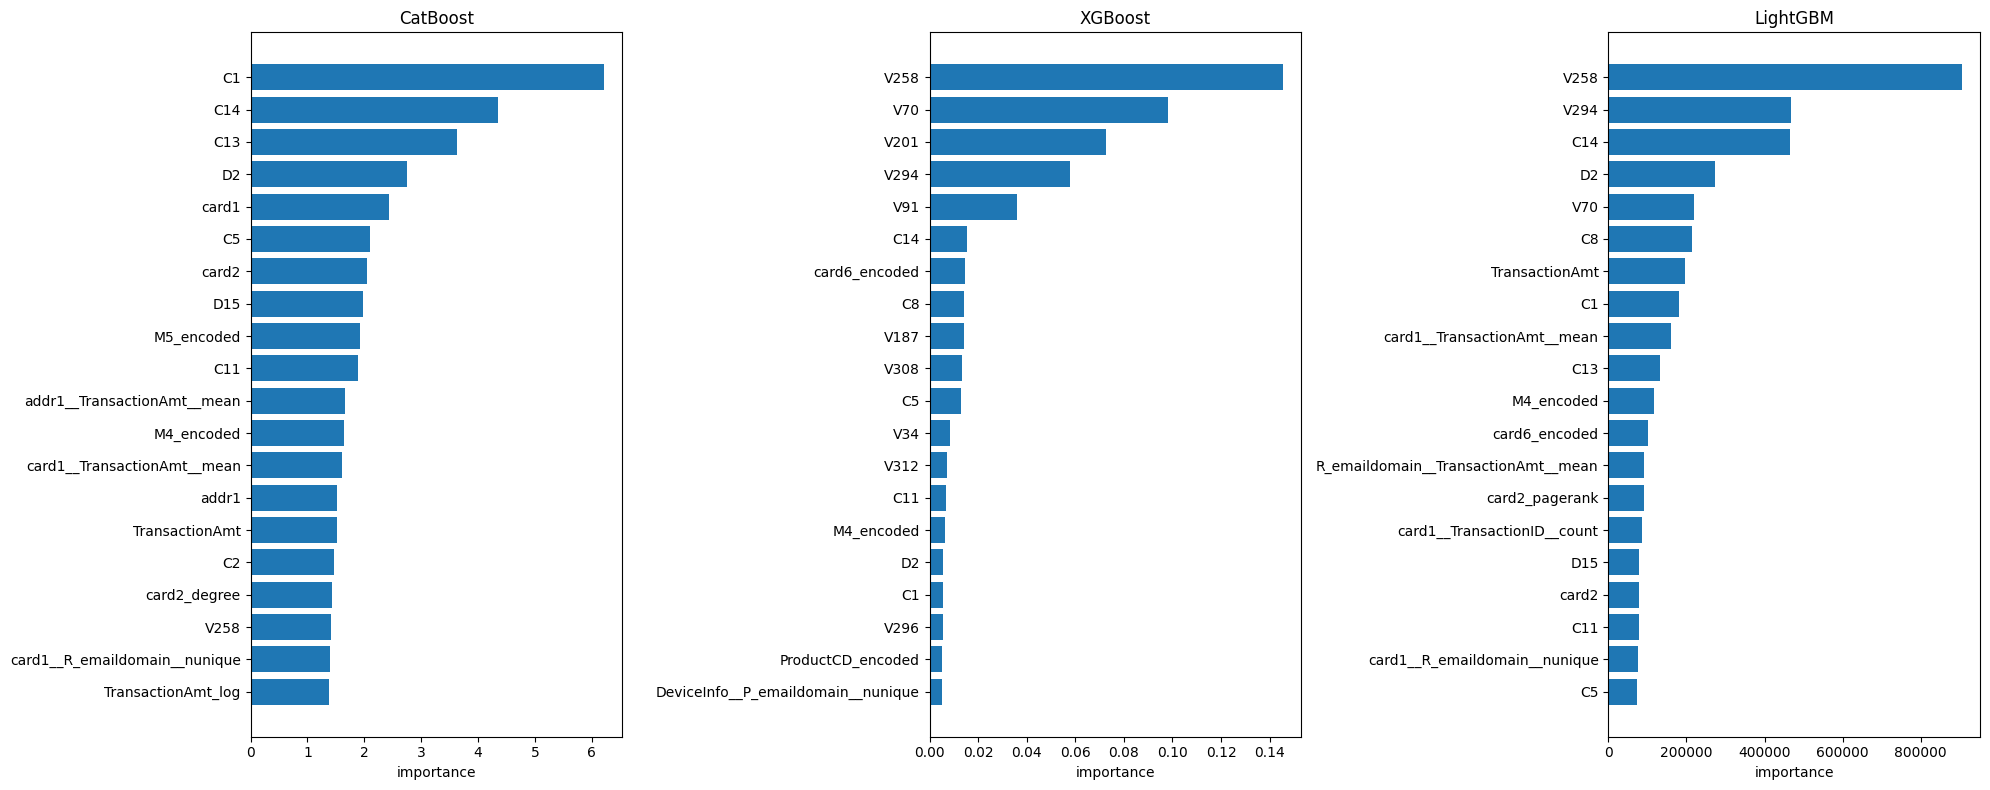

In [19]:
importances = {
    'CatBoost': pd.Series(cat_model.get_feature_importance(), index=X_train.columns),
    'XGBoost': pd.Series(xgb_model.feature_importances_, index=X_train.columns),
    'LightGBM': pd.Series(lgb_model.feature_importance(importance_type='gain'), index=X_train.columns),
}

fig, axes = plt.subplots(1, 3, figsize=(20, 8))
for ax, (name, imp) in zip(axes, importances.items()):
    top20 = imp.sort_values(ascending=False).head(20).sort_values()
    ax.barh(top20.index, top20.values)
    ax.set_title(name)
    ax.set_xlabel('importance')
plt.tight_layout()
plt.savefig(str(config.PLOTS_PATH / 'feature_importance_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
plt.close()

inspect feature names across the three panels to see if the same features dominate or if
each model selects differently. graph features (*_pagerank, *_degree) and aggregation
features (entity__target__agg) should appear alongside original transaction columns.
agreement across models strengthens the case that a feature is genuinely predictive.

## save models

In [20]:
import joblib

models_dir = config.OUTPUT_PATH / 'models'
models_dir.mkdir(exist_ok=True)

joblib.dump(cat_model, str(models_dir / 'catboost_model.pkl'))
joblib.dump(xgb_model, str(models_dir / 'xgboost_model.pkl'))
joblib.dump(lgb_model, str(models_dir / 'lightgbm_model.pkl'))

print(f'saved: catboost_model.pkl')
print(f'saved: xgboost_model.pkl')
print(f'saved: lightgbm_model.pkl')

saved: catboost_model.pkl
saved: xgboost_model.pkl
saved: lightgbm_model.pkl
